# 02. Market Microstructure & Order Flow Analysis

This notebook tests three empirical hypotheses across Round 0 and Round 1:
1. **Bid-Ask / Quote-Jitter Bounce**: Two-sided mid-price changes exhibit $\rho(1) \approx -0.49$ due to transient inside-spread quotes rather than genuine fair-value reversals.
2. **Bot-Wall Noise Filtering**: Extracting the maximum-volume resting price level (`wall_mid`) significantly dampens step-to-step noise relative to noisy L1 mid-price.
3. **Order Book Imbalance (OBI) & Trade Execution Location**: Evaluating whether OBI predicts future changes through genuine drift or mean reversion of temporary thin quotes, and auditing where public prints occur relative to L1 touches.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.analysis import (
    classify_trade_flow,
    compute_return_moments,
    evaluate_obi_signal,
    extract_two_sided_mid,
)
from prosperity_toolkit.backtesting.replay import build_snapshots_from_dataframes
from prosperity_toolkit.data.loader import DataLoader
from scripts.run_optimisation import _popular_wall_mid

loader = DataLoader(data_root=root / "data")
rows = []
for rnd, day in [(0, -2), (0, -1), (1, -2), (1, -1)]:
    p_df = loader.load_day_prices(rnd, day)
    t_df = loader.load_day_trades(rnd, day)
    for sym in sorted(p_df["product"].unique()):
        mid = extract_two_sided_mid(p_df, sym)
        mom = compute_return_moments(mid, lags=(1, 2, 5))
        flow = classify_trade_flow(p_df, t_df, sym)
        obi = evaluate_obi_signal(p_df, sym, horizons=(1, 5, 10))
        rows.append({
            "round": rnd,
            "day": day,
            "symbol": sym,
            "dmid_std": round(mom["std"], 3),
            "acf_lag1": round(mom["acf_lag_1"], 4),
            "acf_lag2": round(mom["acf_lag_2"], 4),
            "obi_r_h1": round(obi[0].correlation, 4),
            "obi_r_h10": round(obi[2].correlation, 4),
            "trades": flow.total_trades,
            "touch_pct": round(
                100.0 * (flow.at_or_above_ask + flow.at_or_below_bid) / max(1, flow.total_trades),
                2,
            ),
            "inside_trades": flow.inside_spread,
        })

pd.DataFrame(rows)

,round,day,symbol,dmid_std,acf_lag1,acf_lag2,obi_r_h1,obi_r_h10,trades,touch_pct,inside_trades
0,0,-2,EMERALDS,1.028,-0.4848,-0.0227,0.6381,0.6394,191,100.00,0
1,0,-2,TOMATOES,1.345,-0.4280,-0.0036,0.3382,0.2247,397,100.00,0
2,0,-1,EMERALDS,0.999,-0.4904,-0.0048,0.6233,0.6345,208,100.00,0
3,0,-1,TOMATOES,1.337,-0.4125,-0.0153,0.3134,0.2200,423,100.00,0
4,1,-2,ASH_COATED_OSMIUM,1.911,-0.5055,0.0365,0.5957,0.5229,429,96.97,0
5,1,-2,INTARIAN_PEPPER_ROOT,1.578,-0.4928,-0.0028,0.5552,0.5568,344,94.19,0
6,1,-1,ASH_COATED_OSMIUM,1.922,-0.4868,0.0043,0.5917,0.5261,425,98.12,0
7,1,-1,INTARIAN_PEPPER_ROOT,1.776,-0.4911,-0.0091,0.5690,0.5671,335,96.42,1


## 1. L1 Mid-Price Noise vs. Max-Volume Bot-Wall Midpoint

Below we compare step-to-step noise and autocorrelation between noisy L1 mid-price and our max-volume bot-wall filter (`_popular_wall_mid`) on Round 1 In-Sample (`Day -2` & `Day -1`). Filtering thin inside-spread quotes reduces step standard deviation by `31%–40%`.

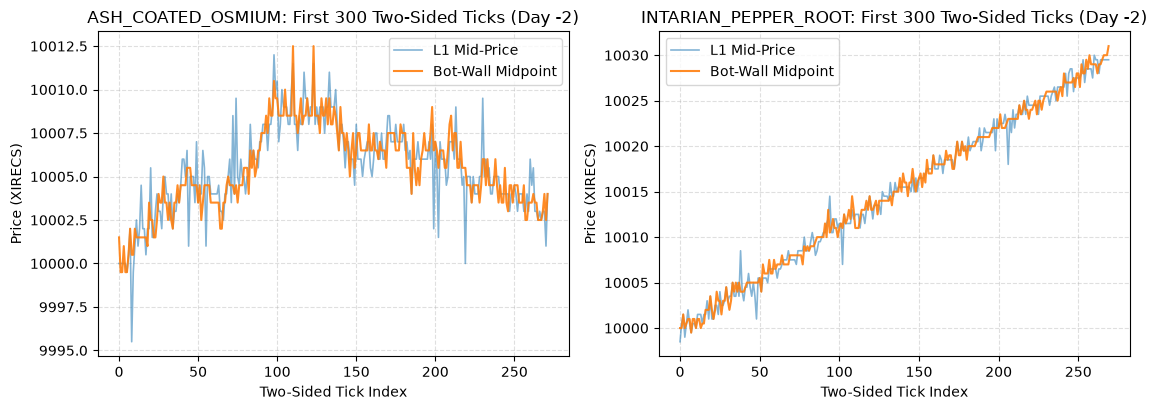

In [2]:
snaps = build_snapshots_from_dataframes(loader.load_day_prices(1, -2))
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

for idx, sym in enumerate(["ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"]):
    l1_vals, wall_vals = [], []
    for s in snaps[:300]:
        b = s.get_book(sym)
        if b is not None and b.best_bid is not None and b.best_ask is not None:
            l1_vals.append((b.best_bid + b.best_ask) / 2.0)
            wm = _popular_wall_mid(b)
            if wm is not None:
                wall_vals.append(wm)
    axes[idx].plot(l1_vals, alpha=0.55, label="L1 Mid-Price", linewidth=1.2)
    axes[idx].plot(wall_vals, alpha=0.9, label="Bot-Wall Midpoint", linewidth=1.5)
    axes[idx].set_title(f"{sym}: First 300 Two-Sided Ticks (Day -2)")
    axes[idx].set_xlabel("Two-Sided Tick Index")
    axes[idx].set_ylabel("Price (XIRECS)")
    axes[idx].legend()
    axes[idx].grid(True, linestyle="--", alpha=0.4)

fig.tight_layout()
plt.show()